# 0. 데이터셋 구축하기

In [ ]:
import pandas as pd

# 화이트 와인 데이터 로드
white_wine_url = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-white.csv"
white_wine = pd.read_csv(white_wine_url, sep=';')

# 레드 와인 데이터 로드
red_wine_url = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv"
red_wine = pd.read_csv(red_wine_url, sep=';')

In [ ]:
# 데이터 구조 확인
print(white_wine.info())
print(red_wine.info())

# 첫 몇 줄 보기
print(white_wine.head())
print(red_wine.head())

NameError: ignored

In [ ]:
#데이터셋에 와인 유형 추가하기
white_wine['wine_type'] = 'white'
red_wine['wine_type'] = 'red'

#데이터셋 병합하기
wine_data = pd.concat([white_wine, red_wine], axis=0)
wine_data.info()

In [ ]:
#병합된 데이터셋 확인
wine_data

# 1. 탐색적 데이터 분석 (EDA)

In [ ]:
#1-1 기초 통계 요약하기
#목적 : 데이터의 중심 경향, 분산 등 기본적인 통계적 특성을 이해하기 위함
print(wine_data.describe())
#수치형 변수의 평균, 표준편차, 최소값, 최대값 등을 보여줌
#-> 이를 통해 데이터의 범위, 중심 위치, 분산 정도를 파악할 수 있음

In [ ]:
#1-2 데이터 분포 확인
#목적: 각 변수의 분포를 이해하고, 이상치나 비정상적인 패턴을 식별하기 위함
import matplotlib.pyplot as plt
import seaborn as sns

# 각 변수의 분포 확인
for column in wine_data.columns:
    plt.figure(figsize=(10, 4))
    sns.histplot(wine_data[column], kde=True)
    plt.title(column)
    plt.show()
#각 변수의 분포를 히스토그램과 커널 밀도 추정(KDE)을 통해 시각화함
#이를 통해 데이터가 어떻게 분포하는지, 왜도(skewness) 또는 첨도(kurtosis)와 같은 특성을 파악할 수 있음

In [ ]:
#1-3 상관 관계 분석
#목적: 변수 간의 관계를 이해하고, 어떤 변수들이 서로 상관 관계를 가지는지 확인하기 위함
plt.figure(figsize=(12, 10))
sns.heatmap(wine_data.corr(), annot=True, fmt=".2f")
plt.show()
#변수 간의 선형 관계의 강도를 확인할 수 있으며, 특정 변수들이 서로 어떻게 연관되어 있는지 파악할 수 있음

In [ ]:
#1-4 와인 유형 별 데이터 비교
#목적: 와인 유형(레드, 화이트)에 따른 데이터의 차이를 파악하기 위함

# 와인 유형 별로 데이터 분포 확인
for column in wine_data.select_dtypes(include='number').columns:
    plt.figure(figsize=(10, 4))
    sns.boxplot(x='wine_type', y=column, data=wine_data)
    plt.title(column)
    plt.show()

#레드 와인과 화이트 와인이 특정 변수에서 어떻게 다른지 확인할 수 있음

In [ ]:
#1-5 이상치 탐색
#목적: 데이터에서 이상치를 식별하여 데이터 품질을 향상시키기 위함

# 이상치 탐색
for column in wine_data.select_dtypes(include='number').columns:
    plt.figure(figsize=(10, 4))
    sns.boxplot(wine_data[column])
    plt.title(column)
    plt.show()

# 전체 프로세스 코드

# 화이트 + 레드 - 업샘플링

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.utils import resample

# 화이트 와인 데이터 로드
white_wine_url = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-white.csv"
white_wine = pd.read_csv(white_wine_url, sep=';')

# 레드 와인 데이터 로드
red_wine_url = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv"
red_wine = pd.read_csv(red_wine_url, sep=';')

# 데이터셋 결합 및 불균형 문제 해결
white_wine['wine_type'] = 'white'  # 화이트 와인 데이터셋에 'white' 표시를 추가
red_wine['wine_type'] = 'red'      # 레드 와인 데이터셋에 'red' 표시를 추가
wine_data = pd.concat([white_wine, red_wine])

# 데이터셋의 클래스 불균형 해결 (예: 'wine_type' 컬럼을 사용한다고 가정)
wine_data['wine_type'] = wine_data['wine_type'].map({'white': 0, 'red': 1})
white_wine = wine_data[wine_data['wine_type'] == 0]
red_wine = wine_data[wine_data['wine_type'] == 1]

# 업샘플링 (레드와인의 수를 화이트와인의 수에 맞춤)
red_wine_upsampled = resample(red_wine,
                              replace=True,
                              n_samples=len(white_wine),
                              random_state=123)

combined_resampled = pd.concat([white_wine, red_wine_upsampled])

# 특성 및 타겟 분리
X = combined_resampled.drop('quality', axis=1)
y = combined_resampled['quality']

# 데이터 분할
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 모델 정의
models = [LinearRegression(), Ridge(), Lasso(), DecisionTreeRegressor(), RandomForestRegressor(), GradientBoostingRegressor()]
model_names = ['LinearRegression', 'Ridge', 'Lasso', 'DecisionTreeRegressor', 'RandomForestRegressor', 'GradientBoostingRegressor']

print("화이트 + 레드 - 업샘플링 데이터셋 결과:")
for model, name in zip(models, model_names):
    # 모델 훈련
    model.fit(X_train, y_train)

    # 예측 및 성능 평가
    y_pred = model.predict(X_test)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)

    print(f'{name}: MSE={mse:.3f}, RMSE={rmse:.3f}, R^2={r2:.3f}')

화이트 + 레드 - 업샘플링 데이터셋 결과:
LinearRegression: MSE=0.495, RMSE=0.704, R^2=0.316
Ridge: MSE=0.497, RMSE=0.705, R^2=0.313
Lasso: MSE=0.723, RMSE=0.850, R^2=-0.000
DecisionTreeRegressor: MSE=0.353, RMSE=0.594, R^2=0.512
RandomForestRegressor: MSE=0.210, RMSE=0.458, R^2=0.710
GradientBoostingRegressor: MSE=0.407, RMSE=0.638, R^2=0.437


# 화이트 + 레드 - 다운샘플링

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.utils import resample

# 화이트 와인 데이터 로드
white_wine_url = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-white.csv"
white_wine = pd.read_csv(white_wine_url, sep=';')

# 레드 와인 데이터 로드
red_wine_url = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv"
red_wine = pd.read_csv(red_wine_url, sep=';')

# 데이터셋 결합 및 불균형 문제 해결
white_wine['wine_type'] = 'white'  # 화이트 와인 데이터셋에 'white' 표시를 추가
red_wine['wine_type'] = 'red'      # 레드 와인 데이터셋에 'red' 표시를 추가
wine_data = pd.concat([white_wine, red_wine])

# 데이터셋의 클래스 불균형 해결 (예: 'wine_type' 컬럼을 사용한다고 가정)
wine_data['wine_type'] = wine_data['wine_type'].map({'white': 0, 'red': 1})
white_wine = wine_data[wine_data['wine_type'] == 0]
red_wine = wine_data[wine_data['wine_type'] == 1]

white_wine_downsampled = resample(white_wine,
                                  replace=False,  # False로 설정하여 복제 없이 샘플링
                                  n_samples=len(red_wine),  # 레드 와인의 샘플 수에 맞춤
                                  random_state=123)  # 재현 가능한 결과를 위해 랜덤 상태 설정

# 다운샘플링된 데이터셋 결합
combined_resampled = pd.concat([white_wine_downsampled, red_wine])

# 특성 및 타겟 분리
X = combined_resampled.drop('quality', axis=1)
y = combined_resampled['quality']

# 데이터 분할
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 모델 정의
models = [LinearRegression(), Ridge(), Lasso(), DecisionTreeRegressor(), RandomForestRegressor(), GradientBoostingRegressor()]
model_names = ['LinearRegression', 'Ridge', 'Lasso', 'DecisionTreeRegressor', 'RandomForestRegressor', 'GradientBoostingRegressor']

print("화이트 + 레드 - 다운샘플링 데이터셋 결과:")
for model, name in zip(models, model_names):
    # 모델 훈련
    model.fit(X_train, y_train)

    # 예측 및 성능 평가
    y_pred = model.predict(X_test)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)

    print(f'{name}: MSE={mse:.3f}, RMSE={rmse:.3f}, R^2={r2:.3f}')

화이트 + 레드 - 다운샘플링 데이터셋 결과:
LinearRegression: MSE=0.474, RMSE=0.688, R^2=0.337
Ridge: MSE=0.478, RMSE=0.692, R^2=0.330
Lasso: MSE=0.716, RMSE=0.846, R^2=-0.003
DecisionTreeRegressor: MSE=0.753, RMSE=0.868, R^2=-0.055
RandomForestRegressor: MSE=0.406, RMSE=0.637, R^2=0.431
GradientBoostingRegressor: MSE=0.447, RMSE=0.668, R^2=0.375


# 화이트 / 레드 개별 성능

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

# 화이트 와인 데이터 로드
white_wine_url = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-white.csv"
white_wine = pd.read_csv(white_wine_url, sep=';')

# 레드 와인 데이터 로드
red_wine_url = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv"
red_wine = pd.read_csv(red_wine_url, sep=';')

# 모델 정의
models = [LinearRegression(), Ridge(), Lasso(), DecisionTreeRegressor(), RandomForestRegressor(), GradientBoostingRegressor()]
model_names = ['LinearRegression', 'Ridge', 'Lasso', 'DecisionTreeRegressor', 'RandomForestRegressor', 'GradientBoostingRegressor']

# 화이트 와인 데이터에 대한 모델 훈련 및 평가
X_white = white_wine.drop('quality', axis=1)
y_white = white_wine['quality']
X_train_white, X_test_white, y_train_white, y_test_white = train_test_split(X_white, y_white, test_size=0.2, random_state=42)

print("화이트 와인 데이터셋 결과:")
for model, name in zip(models, model_names):
    model.fit(X_train_white, y_train_white)
    y_pred_white = model.predict(X_test_white)
    mse_white = mean_squared_error(y_test_white, y_pred_white)
    rmse_white = np.sqrt(mse_white)
    r2_white = r2_score(y_test_white, y_pred_white)
    print(f'{name}: MSE={mse_white:.3f}, RMSE={rmse_white:.3f}, R^2={r2_white:.3f}')

# 레드 와인 데이터에 대한 모델 훈련 및 평가
X_red = red_wine.drop('quality', axis=1)
y_red = red_wine['quality']
X_train_red, X_test_red, y_train_red, y_test_red = train_test_split(X_red, y_red, test_size=0.2, random_state=42)

print("\n레드 와인 데이터셋 결과:")
for model, name in zip(models, model_names):
    model.fit(X_train_red, y_train_red)
    y_pred_red = model.predict(X_test_red)
    mse_red = mean_squared_error(y_test_red, y_pred_red)
    rmse_red = np.sqrt(mse_red)
    r2_red = r2_score(y_test_red, y_pred_red)
    print(f'{name}: MSE={mse_red:.3f}, RMSE={rmse_red:.3f}, R^2={r2_red:.3f}')

화이트 와인 데이터셋 결과:
LinearRegression: MSE=0.569, RMSE=0.754, R^2=0.265
Ridge: MSE=0.583, RMSE=0.763, R^2=0.248
Lasso: MSE=0.737, RMSE=0.858, R^2=0.049
DecisionTreeRegressor: MSE=0.688, RMSE=0.829, R^2=0.112
RandomForestRegressor: MSE=0.346, RMSE=0.588, R^2=0.553
GradientBoostingRegressor: MSE=0.462, RMSE=0.680, R^2=0.403

레드 와인 데이터셋 결과:
LinearRegression: MSE=0.390, RMSE=0.625, R^2=0.403
Ridge: MSE=0.393, RMSE=0.627, R^2=0.399
Lasso: MSE=0.648, RMSE=0.805, R^2=0.009
DecisionTreeRegressor: MSE=0.650, RMSE=0.806, R^2=0.005
RandomForestRegressor: MSE=0.313, RMSE=0.559, R^2=0.521
GradientBoostingRegressor: MSE=0.362, RMSE=0.602, R^2=0.446


# 화이트 + 레드 - 업샘플링 + 특성 추가(1)

In [ ]:
# <양의 corr>
# 1.  Fixed acidity과 residual sugar의 양이 많아질 수록 density가 올라감.
# (각각0.46/0.55, sugar가 밀도에 조금 더 많은 영향을 끼침  )
# Residual sugar와 free sulfur dioxide의 양이 많아질수록 total sulfur dioxide가 올라감.
# (각각 0.50/0.72, free sulfur dioxide가 가장 많은 영향을 끼침)
# Residual sugar는 density와 total sulfur dioxide 둘 다 유의적인 상관관계를 가짐.

# <음의 corr>
# density가 커질수록 alcohol은 작아짐.   (-0.69으로 두번째로 큰 상관계수)

# Fixed acidity와 residual sugar의 합을 새로운 특성으로 추가하여 density에 미치는 영향을 반영합니다.
# Residual sugar와 free sulfur dioxide의 합을 새로운 특성으로 추가하여 total sulfur dioxide에 미치는 영향을 반영합니다.
# Density가 증가함에 따라 alcohol이 감소하는 경향을 반영하는 새로운 특성을 추가합니다.

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.utils import resample

# 화이트 와인 데이터 로드
white_wine_url = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-white.csv"
white_wine = pd.read_csv(white_wine_url, sep=';')

# 레드 와인 데이터 로드
red_wine_url = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv"
red_wine = pd.read_csv(red_wine_url, sep=';')

# 데이터셋 결합 및 불균형 문제 해결
white_wine['wine_type'] = 'white'  # 화이트 와인 데이터셋에 'white' 표시를 추가
red_wine['wine_type'] = 'red'      # 레드 와인 데이터셋에 'red' 표시를 추가
wine_data = pd.concat([white_wine, red_wine])

# 데이터셋의 클래스 불균형 해결 (예: 'wine_type' 컬럼을 사용한다고 가정)
wine_data['wine_type'] = wine_data['wine_type'].map({'white': 0, 'red': 1})
white_wine = wine_data[wine_data['wine_type'] == 0]
red_wine = wine_data[wine_data['wine_type'] == 1]

# 업샘플링 (레드와인의 수를 화이트와인의 수에 맞춤)
red_wine_upsampled = resample(red_wine,
                              replace=True,
                              n_samples=len(white_wine),
                              random_state=123)

combined_resampled = pd.concat([white_wine, red_wine_upsampled])

# 새로운 특성 생성
combined_resampled['acidity_sugar_sum'] = combined_resampled['fixed acidity'] + combined_resampled['residual sugar']
combined_resampled['sugar_sulfur_sum'] = combined_resampled['residual sugar'] + combined_resampled['free sulfur dioxide']
combined_resampled['inverse_density'] = 1 / combined_resampled['density']

# 피처 엔지니어링: 상관관계에 기반한 새로운 특성 생성
combined_resampled['acidity_sugar_interaction'] = combined_resampled['fixed acidity'] * combined_resampled['residual sugar']
combined_resampled['sulfur_dioxide_interaction'] = combined_resampled['free sulfur dioxide'] * combined_resampled['total sulfur dioxide']
combined_resampled['inverse_alcohol_density_interaction'] = 1 / (combined_resampled['density'] * combined_resampled['alcohol'])

# 특성 및 타겟 분리
X = combined_resampled.drop(['quality', 'wine_type'], axis=1)  # 'wine_type' 컬럼 제거
y = combined_resampled['quality']

# 데이터 분할
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("화이트 + 레드 - 업샘플링 + 특성 추가(1)")

# 모델 정의
models = [LinearRegression(), Ridge(), Lasso(), DecisionTreeRegressor(), RandomForestRegressor(), GradientBoostingRegressor()]
model_names = ['LinearRegression', 'Ridge', 'Lasso', 'DecisionTreeRegressor', 'RandomForestRegressor', 'GradientBoostingRegressor']

for model, name in zip(models, model_names):
    # 모델 훈련
    model.fit(X_train, y_train)

    # 예측 및 성능 평가
    y_pred = model.predict(X_test)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)

    print(f'{name}: MSE={mse:.3f}, RMSE={rmse:.3f}, R^2={r2:.3f}')

화이트 + 레드 - 업샘플링 + 특성 추가(1)
LinearRegression: MSE=0.494, RMSE=0.703, R^2=0.316
Ridge: MSE=0.497, RMSE=0.705, R^2=0.313
Lasso: MSE=0.723, RMSE=0.850, R^2=-0.000
DecisionTreeRegressor: MSE=0.411, RMSE=0.641, R^2=0.431
RandomForestRegressor: MSE=0.215, RMSE=0.463, R^2=0.703
GradientBoostingRegressor: MSE=0.408, RMSE=0.639, R^2=0.435


<ipython-input-10-42f0c67ec5bc>:29: FutureWarning: The default value of numeric_only in DataFrame.corr is deprecated. In a future version, it will default to False. Select only valid columns or specify the value of numeric_only to silence this warning.
  sns.heatmap(wine_data.corr(), annot=True, fmt=".2f",cmap='Blues')


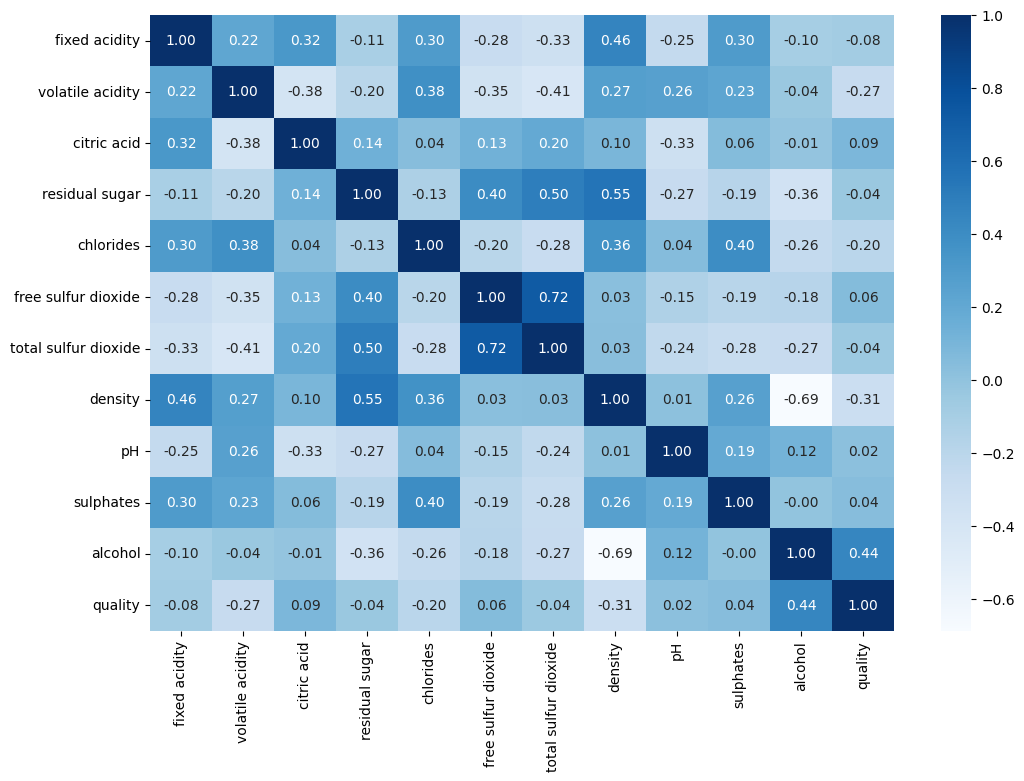

In [ ]:
import pandas as pd

# 화이트 와인 데이터 로드
white_wine_url = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-white.csv"
white_wine = pd.read_csv(white_wine_url, sep=';')
data_white = pd.read_csv(white_wine_url, sep=';')

# 레드 와인 데이터 로드
red_wine_url = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv"
red_wine = pd.read_csv(red_wine_url, sep=';')

#데이터셋에 와인 유형 추가하기
white_wine['wine_type'] = 'white'
red_wine['wine_type'] = 'red'

#데이터셋 병합하기
wine_data = pd.concat([white_wine, red_wine], axis=0)

# 병합된 데이터셋 확인
wine_data

import seaborn as sns
import matplotlib.pyplot as plt

# 변수 간의 관계 파악
# 색이 진할수록 두 변수 간의 상관 관계가 더 강하다는 것을 의미함
# 이를 통해 어떤 변수가 와인의 품질에 더 큰 영향을 미치는지 파악할 수 있음
plt.figure(figsize=(12, 8))
sns.heatmap(wine_data.corr(), annot=True, fmt=".2f",cmap='Blues')
plt.show()

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.utils import resample

# 화이트 와인 데이터 로드
white_wine_url = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-white.csv"
white_wine = pd.read_csv(white_wine_url, sep=';')

# 레드 와인 데이터 로드
red_wine_url = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv"
red_wine = pd.read_csv(red_wine_url, sep=';')

# 데이터셋 결합 및 불균형 문제 해결
white_wine['wine_type'] = 'white'  # 화이트 와인 데이터셋에 'white' 표시를 추가
red_wine['wine_type'] = 'red'      # 레드 와인 데이터셋에 'red' 표시를 추가
wine_data = pd.concat([white_wine, red_wine])

# 데이터셋의 클래스 불균형 해결 (예: 'wine_type' 컬럼을 사용한다고 가정)
wine_data['wine_type'] = wine_data['wine_type'].map({'white': 0, 'red': 1})
white_wine = wine_data[wine_data['wine_type'] == 0]
red_wine = wine_data[wine_data['wine_type'] == 1]

# 업샘플링 (레드와인의 수를 화이트와인의 수에 맞춤)
red_wine_upsampled = resample(red_wine,
                              replace=True,
                              n_samples=len(white_wine),
                              random_state=123)

combined_resampled = pd.concat([white_wine, red_wine_upsampled])

# # 새로운 특성 생성
# combined_resampled['acidity_sugar_sum'] = combined_resampled['fixed acidity'] + combined_resampled['residual sugar']
# combined_resampled['sugar_sulfur_sum'] = combined_resampled['residual sugar'] + combined_resampled['free sulfur dioxide']
# combined_resampled['inverse_density'] = 1 / combined_resampled['density']

# 피처 엔지니어링: 상관관계에 기반한 새로운 특성 생성
combined_resampled['acidity_sugar_interaction'] = combined_resampled['fixed acidity'] * combined_resampled['residual sugar']
combined_resampled['sulfur_dioxide_interaction'] = combined_resampled['free sulfur dioxide'] * combined_resampled['total sulfur dioxide']
combined_resampled['inverse_alcohol_density_interaction'] = 1 / (combined_resampled['density'] * combined_resampled['alcohol'])

# 특성 및 타겟 분리
X = combined_resampled.drop(['quality', 'wine_type'], axis=1)  # 'wine_type' 컬럼 제거
y = combined_resampled['quality']

# 데이터 분할
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("화이트 + 레드 - 업샘플링 + 특성 추가(2)")

# 모델 정의
models = [LinearRegression(), Ridge(), Lasso(), DecisionTreeRegressor(), RandomForestRegressor(), GradientBoostingRegressor()]
model_names = ['LinearRegression', 'Ridge', 'Lasso', 'DecisionTreeRegressor', 'RandomForestRegressor', 'GradientBoostingRegressor']

for model, name in zip(models, model_names):
    # 모델 훈련
    model.fit(X_train, y_train)

    # 예측 및 성능 평가
    y_pred = model.predict(X_test)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)

    print(f'{name}: MSE={mse:.3f}, RMSE={rmse:.3f}, R^2={r2:.3f}')

화이트 + 레드 - 업샘플링 + 특성 추가(2)
LinearRegression: MSE=0.494, RMSE=0.703, R^2=0.317
Ridge: MSE=0.496, RMSE=0.704, R^2=0.314
Lasso: MSE=0.723, RMSE=0.850, R^2=-0.000
DecisionTreeRegressor: MSE=0.401, RMSE=0.633, R^2=0.446
RandomForestRegressor: MSE=0.207, RMSE=0.455, R^2=0.714
GradientBoostingRegressor: MSE=0.406, RMSE=0.637, R^2=0.439


In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.utils import resample

# 화이트 와인 데이터 로드
white_wine_url = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-white.csv"
white_wine = pd.read_csv(white_wine_url, sep=';')

# 레드 와인 데이터 로드
red_wine_url = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv"
red_wine = pd.read_csv(red_wine_url, sep=';')

# 데이터셋 결합 및 불균형 문제 해결
white_wine['wine_type'] = 'white'  # 화이트 와인 데이터셋에 'white' 표시를 추가
red_wine['wine_type'] = 'red'      # 레드 와인 데이터셋에 'red' 표시를 추가
wine_data = pd.concat([white_wine, red_wine])

# 데이터셋의 클래스 불균형 해결 (예: 'wine_type' 컬럼을 사용한다고 가정)
wine_data['wine_type'] = wine_data['wine_type'].map({'white': 0, 'red': 1})
white_wine = wine_data[wine_data['wine_type'] == 0]
red_wine = wine_data[wine_data['wine_type'] == 1]

# 업샘플링 (레드와인의 수를 화이트와인의 수에 맞춤)
red_wine_upsampled = resample(red_wine,
                              replace=True,
                              n_samples=len(white_wine),
                              random_state=123)

combined_resampled = pd.concat([white_wine, red_wine_upsampled])

# 새로운 특성 생성
combined_resampled['acidity_sugar_sum'] = combined_resampled['fixed acidity'] + combined_resampled['residual sugar']
combined_resampled['sugar_sulfur_sum'] = combined_resampled['residual sugar'] + combined_resampled['free sulfur dioxide']
combined_resampled['inverse_density'] = 1 / combined_resampled['density']

# 피처 엔지니어링: 상관관계에 기반한 새로운 특성 생성
combined_resampled['acidity_sugar_interaction'] = combined_resampled['fixed acidity'] * combined_resampled['residual sugar']
combined_resampled['sulfur_dioxide_interaction'] = combined_resampled['free sulfur dioxide'] * combined_resampled['total sulfur dioxide']
combined_resampled['inverse_alcohol_density_interaction'] = 1 / (combined_resampled['density'] * combined_resampled['alcohol'])

# 특성 및 타겟 분리
X = combined_resampled.drop(['quality', 'wine_type'], axis=1)  # 'wine_type' 컬럼 제거
y = combined_resampled['quality']

# 데이터 분할
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("화이트 + 레드 - 업샘플링 + 특성 추가(3)")

# 모델 정의
models = [LinearRegression(), Ridge(), Lasso(), DecisionTreeRegressor(), RandomForestRegressor(), GradientBoostingRegressor()]
model_names = ['LinearRegression', 'Ridge', 'Lasso', 'DecisionTreeRegressor', 'RandomForestRegressor', 'GradientBoostingRegressor']

for model, name in zip(models, model_names):
    # 모델 훈련
    model.fit(X_train, y_train)

    # 예측 및 성능 평가
    y_pred = model.predict(X_test)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)

    print(f'{name}: MSE={mse:.3f}, RMSE={rmse:.3f}, R^2={r2:.3f}')

화이트 + 레드 - 업샘플링 + 특성 추가(3)
LinearRegression: MSE=0.494, RMSE=0.703, R^2=0.317
Ridge: MSE=0.496, RMSE=0.704, R^2=0.314
Lasso: MSE=0.723, RMSE=0.850, R^2=-0.000
DecisionTreeRegressor: MSE=0.412, RMSE=0.642, R^2=0.431
RandomForestRegressor: MSE=0.208, RMSE=0.456, R^2=0.712
GradientBoostingRegressor: MSE=0.408, RMSE=0.639, R^2=0.436


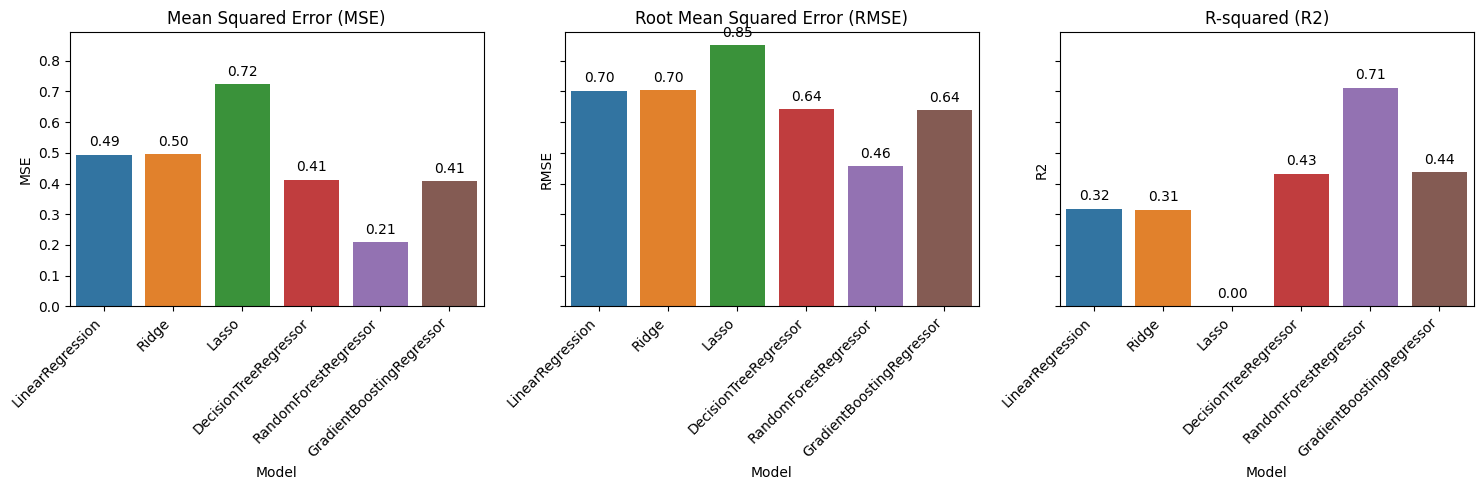

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 모델 성능 결과를 데이터 프레임으로 생성
results = {
    'Model': ['LinearRegression', 'Ridge', 'Lasso', 'DecisionTreeRegressor', 'RandomForestRegressor', 'GradientBoostingRegressor'],
    'MSE': [0.494, 0.496, 0.723, 0.412, 0.208, 0.408],
    'RMSE': [0.703, 0.704, 0.850, 0.642, 0.456, 0.639],
    'R2': [0.317, 0.314, -0.000, 0.431, 0.712, 0.436]
}

df_results = pd.DataFrame(results)

# MSE, RMSE, R2에 대한 바 그래프를 그립니다.
fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(15, 5), sharey=True)
sns.barplot(x='Model', y='MSE', data=df_results, ax=axes[0])
sns.barplot(x='Model', y='RMSE', data=df_results, ax=axes[1])
sns.barplot(x='Model', y='R2', data=df_results, ax=axes[2])

# 그래프의 레이아웃을 개선합니다.
for ax in axes:
    for p in ax.patches:
        ax.annotate(format(p.get_height(), '.2f'),
                    (p.get_x() + p.get_width() / 2., p.get_height()),
                    ha = 'center', va = 'center',
                    xytext = (0, 9),
                    textcoords = 'offset points')
    plt.setp(ax.get_xticklabels(), rotation=45, horizontalalignment='right')

# 타이틀 설정
axes[0].set_title('Mean Squared Error (MSE)')
axes[1].set_title('Root Mean Squared Error (RMSE)')
axes[2].set_title('R-squared (R2)')

# 그래프 표시
plt.tight_layout()
plt.show()

In [ ]:
# Mean Squared Error (MSE):

# MSE는 예측 값과 실제 값의 차이의 제곱에 대한 평균을 나타냅니다. 값이 낮을수록 모델의 예측 정확도가 높다는 것을 의미합니다.
# RandomForestRegressor가 가장 낮은 MSE를 기록하여 이 데이터셋에 대해 가장 좋은 예측 성능을 보였습니다.
# Lasso 회귀는 가장 높은 MSE를 가지며, 이는 다른 모델들에 비해 예측 성능이 가장 낮음을 나타냅니다.
# Root Mean Squared Error (RMSE):

# RMSE는 MSE의 제곱근으로, 예측 오차의 크기를 실제 측정값과 동일한 단위로 표현합니다. MSE와 마찬가지로 RMSE가 낮을수록 모델의 예측 성능이 좋다는 것을 의미합니다.
# RandomForestRegressor가 다시 한 번 가장 낮은 RMSE를 기록하며, 이는 실제 값과 예측 값 간의 평균적인 오차가 가장 적음을 의미합니다.
# Lasso 회귀는 이 지표에서도 가장 높은 값을 보여, 예측에 있어서 가장 큰 오차를 가지고 있음을 나타냅니다.
# R-squared (R²):

# R²는 결정 계수로서, 모델이 데이터의 변동성을 얼마나 잘 설명하는지를 나타냅니다. 0에서 1 사이의 값을 가지며, 1에 가까울수록 모델이 데이터를 더 잘 설명한다는 것을 의미합니다.
# RandomForestRegressor는 이 지표에서도 가장 높은 값을 보여, 데이터셋의 변동성을 가장 잘 설명하는 모델임을 나타냅니다.
# Lasso 회귀는 0에 가까운 R² 값을 가지며, 이는 모델이 데이터의 변동성을 거의 설명하지 못함을 의미합니다.

In [ ]:
# 데이터셋의 복잡성: RandomForestRegressor는 복잡한 패턴과 관계를 포함할 수 있는 데이터셋에 잘 작동하는 경향이 있습니다.
#이 모델이 가장 좋은 성능을 보인다는 것은, 와인 데이터셋에 다양한 특성 간의 복잡한 상호작용이 존재할 수 있음을 의미합니다.
#RandomForest는 여러 결정 트리를 결합하여 작동하기 때문에, 각각의 트리가 데이터의 다른 측면을 학습하고,
#이를 종합하여 보다 정확한 예측을 할 수 있습니다.

# 모델의 유연성과 일반화 능력: RandomForestRegressor가 다양한 조건(다른 샘플링 방법 및 특성 추가)에서 일관되게
#낮은 MSE를 달성한다는 것은 이 모델이 데이터의 일반화에 매우 효과적임을 나타냅니다.
#이는 모델이 훈련 데이터에 과적합되지 않고, 새로운 데이터에 대해서도 잘 예측할 수 있음을 시사합니다.

# 오차율의 해석: MSE(Mean Squared Error)는 예측값과 실제값의 차이의 제곱을 평균낸 값입니다.
#RandomForestRegressor가 낮은 MSE 값을 기록한다는 것은, 예측 오차가 다른 모델에 비해 평균적으로
#더 작다는 것을 의미합니다. 이는 와인의 품질을 평가하는 데 있어 RandomForest 모델이 더 신뢰할 수 있는 예측을 제공한다는 것을 나타냅니다.

# 특성 추가의 영향: 특성 추가에 따른 성능 변화를 관찰하여,
#데이터셋에 새로운 정보를 추가하는 것이 모델의 예측 능력에 긍정적인 영향을 미칠 수 있음을 확인할 수 있습니다.
#이는 추가된 특성이 유의미하고, 와인의 품질 예측에 중요한 요소를 포함하고 있을 수 있음을 시사합니다.

# 이러한 분석을 바탕으로, 다른 모델에 비해 RandomForestRegressor가 이 데이터셋의 특성을 가장 잘 포착하고 있으며,
#와인 품질 예측에 있어서 가장 신뢰할 수 있는 선택이 될 수 있음을 알 수 있습니다.
#이는 또한 와인 데이터셋의 특성 선택과 새로운 특성 엔지니어링이 예측 모델의 성능을 향상시키는 중요한 요소임을 강조합니다.

# 신뢰구간

In [ ]:
from sklearn.utils import resample
from sklearn.metrics import mean_squared_error
import numpy as np

import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.utils import resample

# 화이트 와인 데이터 로드
white_wine_url = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-white.csv"
white_wine = pd.read_csv(white_wine_url, sep=';')

# 레드 와인 데이터 로드
red_wine_url = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv"
red_wine = pd.read_csv(red_wine_url, sep=';')

# 데이터셋 결합 및 불균형 문제 해결
white_wine['wine_type'] = 'white'  # 화이트 와인 데이터셋에 'white' 표시를 추가
red_wine['wine_type'] = 'red'      # 레드 와인 데이터셋에 'red' 표시를 추가
wine_data = pd.concat([white_wine, red_wine])

# 데이터셋의 클래스 불균형 해결 (예: 'wine_type' 컬럼을 사용한다고 가정)
wine_data['wine_type'] = wine_data['wine_type'].map({'white': 0, 'red': 1})
white_wine = wine_data[wine_data['wine_type'] == 0]
red_wine = wine_data[wine_data['wine_type'] == 1]

# 업샘플링 (레드와인의 수를 화이트와인의 수에 맞춤)
red_wine_upsampled = resample(red_wine,
                              replace=True,
                              n_samples=len(white_wine),
                              random_state=123)

combined_resampled = pd.concat([white_wine, red_wine_upsampled])

# 새로운 특성 생성
combined_resampled['acidity_sugar_sum'] = combined_resampled['fixed acidity'] + combined_resampled['residual sugar']
combined_resampled['sugar_sulfur_sum'] = combined_resampled['residual sugar'] + combined_resampled['free sulfur dioxide']
combined_resampled['inverse_density'] = 1 / combined_resampled['density']

# 피처 엔지니어링: 상관관계에 기반한 새로운 특성 생성
combined_resampled['acidity_sugar_interaction'] = combined_resampled['fixed acidity'] * combined_resampled['residual sugar']
combined_resampled['sulfur_dioxide_interaction'] = combined_resampled['free sulfur dioxide'] * combined_resampled['total sulfur dioxide']
combined_resampled['inverse_alcohol_density_interaction'] = 1 / (combined_resampled['density'] * combined_resampled['alcohol'])

# 특성 및 타겟 분리
X = combined_resampled.drop(['quality', 'wine_type'], axis=1)  # 'wine_type' 컬럼 제거
y = combined_resampled['quality']

# 데이터 분할
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 부트스트랩을 사용한 신뢰구간 계산 함수
def bootstrap_confidence_interval(model, X, y, n_bootstrap=1000, ci=95):
    bootstrap_estimates = []
    for _ in range(n_bootstrap):
        # 부트스트랩 샘플 생성
        X_sample, y_sample = resample(X, y)
        # 모델 훈련 및 예측
        model.fit(X_sample, y_sample)
        y_pred = model.predict(X)
        mse = mean_squared_error(y, y_pred)
        bootstrap_estimates.append(mse)

    # 신뢰구간 계산
    lower = np.percentile(bootstrap_estimates, (100-ci)/2)
    upper = np.percentile(bootstrap_estimates, 100-(100-ci)/2)
    return lower, upper

# 모델 및 데이터셋 설정
rf_model = RandomForestRegressor(random_state=42)
# X_train, y_train = ... # 데이터셋 설정 필요

# 95% 신뢰구간 계산
lower_bound, upper_bound = bootstrap_confidence_interval(rf_model, X_train, y_train)
print(f"95% confidence interval for the MSE: [{lower_bound:.3f}, {upper_bound:.3f}]")


95% confidence interval for the MSE: [0.100, 0.118]
